# 04 · CNN desde cero (CRISP-DM fase 4)

**Objetivo:** documentar la red convolucional: arquitectura, búsqueda de hiperparámetros, curvas de aprendizaje y qué regiones de la imagen usa (Grad-CAM).

El entrenamiento se hace con `python -m src.training.train_cnn` (≈ 40 min en CPU para el modelo final). Este notebook **no reentrena**: carga el modelo `experiments/checkpoints/cnn.pt` y los resultados de `experiments/results/`.

In [1]:
import os, json, glob
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src.utils.paths import RESULTS, CHECKPOINTS, SPLITS_PATH
from src.utils import plotting
from src.models.cnn import FruitCNN, count_parameters
from src.models.predictor import Predictor
from src.data.preprocess import load_split
from src.evaluation.metrics import CLASSES, FRUIT_ES, encode
from src.evaluation.gradcam import GradCAM
from src.features.handcrafted import border_mask
plotting.setup()

## 1. Arquitectura

Tres bloques Conv → BatchNorm → ReLU → MaxPool, *global average pooling* y una cabeza densa pequeña. Se recorre la red con una entrada de 96×96 para ver la forma de cada salida y los parámetros por capa.

In [2]:
net = FruitCNN()
x = torch.zeros(1, 3, 96, 96)
rows = []
for name, layer in [*[(f"bloque {i+1}", b) for i, b in enumerate(net.features)], ("GAP", net.pool), ("cabeza densa", net.head)]:
    x = layer(x)
    rows.append({"capa": name, "salida": tuple(x.shape[1:]), "parámetros": count_parameters(layer)})
pd.DataFrame(rows).assign(**{"% del total": lambda d: (100 * d["parámetros"] / count_parameters(net)).round(1)})

,capa,salida,parámetros,% del total
0,bloque 1,"(32, 48, 48)",2464,2.2
1,bloque 2,"(64, 24, 24)",18560,16.4
2,bloque 3,"(128, 12, 12)",73984,65.4
3,GAP,"(128, 1, 1)",0,0.0
4,cabeza densa,"(12,)",18060,16.0


El 84 % de los 113.068 parámetros (95.008) están en las convoluciones y solo 18.060 en la cabeza densa, gracias al *global average pooling* (aplanar 128×12×12 habría puesto ~2,4 M de parámetros en la primera capa densa). Para comparar: la regresión logística sobre 418 características tiene 418·12 + 12 = 5.028 parámetros, y la CNN aprende sus propias características a partir de los píxeles.

## 2. Búsqueda de hiperparámetros

Rejilla 2×2 (tasa de aprendizaje × *dropout*), 12 épocas cada una, seleccionando por F1-macro de validación.

In [3]:
rows = []
for f in sorted(glob.glob(str(RESULTS / "metrics_cnn_lr*.json"))):
    d = json.load(open(f))
    rows.append({"lr": d["params"]["lr"], "dropout": d["params"]["dropout"],
                 "F1 train": d["train"]["joint_f1_macro"], "F1 val": d["val"]["joint_f1_macro"],
                 "acc. calidad val": d["val"]["quality_accuracy"], "min": d["train_seconds"] / 60})
grid = pd.DataFrame(rows).sort_values("F1 val", ascending=False)
grid.round(3)

,lr,dropout,F1 train,F1 val,acc. calidad val,min
0,0.001,0.3,0.876,0.828,0.922,14.838
2,0.003,0.3,0.886,0.810,0.928,14.242
1,0.001,0.5,0.854,0.809,0.914,14.032
3,0.003,0.5,0.852,0.782,0.912,14.450


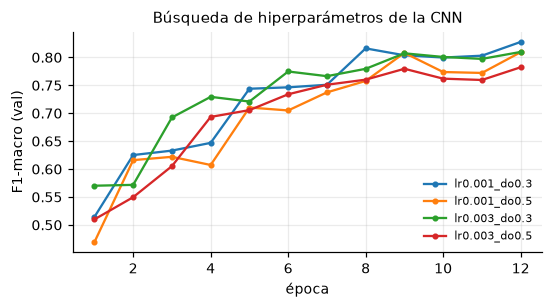

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 2.6))
for f in sorted(glob.glob(str(RESULTS / "history_cnn_lr*.csv"))):
    h = pd.read_csv(f)
    ax.plot(h.epoch, h.val_f1_macro, marker="o", ms=3, label=Path(f).stem.replace("history_cnn_", ""))
ax.set_xlabel("época"); ax.set_ylabel("F1-macro (val)"); ax.legend(frameon=False, fontsize=7)
ax.set_title("Búsqueda de hiperparámetros de la CNN")
plotting.save(fig, "cnn_busqueda")

Dropout 0,3 gana con ambas tasas, y $\eta_0 = 10^{-3}$ gana con ambos *dropouts*. Como en las cuatro corridas el F1 seguía subiendo en la época 12, el modelo final se entrena hasta 35 épocas con parada temprana.

## 3. Modelo final: curvas de aprendizaje

In [5]:
M = json.load(open(RESULTS / "metrics_cnn.json"))
h = pd.read_csv(RESULTS / "history_cnn.csv")
print(f"Mejor época: {M['best_epoch']} de {len(h)} · tiempo: {M['train_seconds']/60:.1f} min · {M['n_parameters']:,} parámetros")
pd.DataFrame({s: {k: M[s][k] for k in ["joint_f1_macro", "joint_accuracy", "quality_accuracy", "quality_roc_auc", "fruit_accuracy"]}
              for s in ["train", "val", "test"]}).round(3)

Mejor época: 34 de 35 · tiempo: 40.4 min · 113,068 parámetros


,train,val,test
joint_f1_macro,0.947,0.881,0.909
joint_accuracy,0.947,0.882,0.905
quality_accuracy,0.978,0.962,0.958
quality_roc_auc,0.998,0.992,0.994
fruit_accuracy,0.960,0.906,0.932


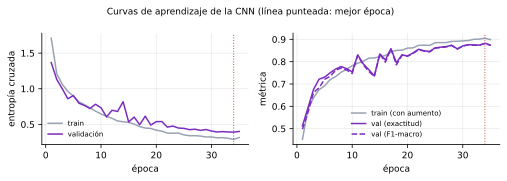

In [6]:
from IPython.display import SVG, display
display(SVG(filename="reports/figures/res_curvas_cnn.svg"))

- **Sin sobreajuste apreciable:** la pérdida de validación baja junto con la de entrenamiento durante las 35 épocas, y el F1 de train (0,947, medido sin aumento) está solo 6,6 puntos por encima del de validación. En los modelos clásicos esa brecha es de 12–14 puntos.
- La exactitud de train **con** aumento (curva gris) queda por debajo de la de validación al principio: las imágenes aumentadas son más difíciles que las originales.
- La mejor época es la 34 de 35: la red **aún no había convergido**. Con más épocas probablemente mejoraría; no se hizo por el costo en CPU (≈ 70 s por época, 40 min en total).
- Los saltos de la curva de validación entre las épocas 10 y 20 se suavizan cuando la tasa de aprendizaje baja con el decaimiento coseno.

## 4. ¿Qué mira la red? Grad-CAM

Grad-CAM pondera los mapas de activación del último bloque convolucional por el gradiente de la clase predicha:

$$\alpha_k = \frac{1}{Z}\sum_{u,v} \frac{\partial z_c}{\partial A^k_{uv}}, \qquad L_{\text{Grad-CAM}} = \mathrm{ReLU}\Big(\sum_k \alpha_k A^k\Big)$$

Para cuantificar el sesgo de fondo se mide qué fracción de la "energía" del mapa cae en el anillo de 16 px del borde (que ocupa el 44 % del área de la imagen). Si la red mirara al azar, la fracción sería ≈ 0,44; si se concentra en la fruta (normalmente centrada), debería ser menor.

In [7]:
S = json.load(open(RESULTS / "resumen_evaluacion.json"))
pd.Series(S["gradcam"]).round(3).to_frame("Grad-CAM (test)")

,Grad-CAM (test)
border_ring_area_fraction,0.438
mean_border_energy,0.259
median_border_energy,0.285
frac_images_border_energy_gt_area,0.051


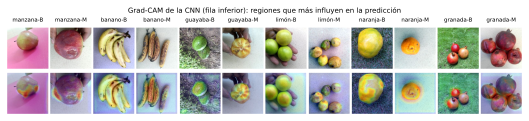

In [8]:
display(SVG(filename="reports/figures/res_gradcam.svg"))

La energía media en el borde es **0,26**, frente a 0,44 si la red mirara al azar: concentra ~40 % menos atención en el fondo de lo esperado, y solo el 5 % de las imágenes tiene más energía en el borde que su área. En los ejemplos, los mapas caen sobre las manchas del banano, la podredumbre de la guayaba y la textura de la naranja. Es una buena señal frente al sesgo de fondo de la fase 2, aunque no lo elimina: los errores más confiados de la CNN (notebook 05) incluyen frutas sostenidas en la mano, lo que indica que el contexto de la sesión todavía influye.